In [99]:
import pandas as pd
import yaml
import subprocess
from IPython.display import display

In [100]:
REGENERATE_RULES = False 
REGENERATE_INDEX_RULES = False
INDEX_YML_PATH = "../data/diachronica/index_diachronica.yml"
RULES_YML_PATH = "data/asca_rules.yml"
RULES_CSV_PATH = "data/asca_rules.csv"
INDEX_RULES_CSV_PATH = "data/index_rules.csv"
DF_COLS = ["section_index", "section_name", "rule_id", "step_index", "c_index", "input", "output", "env", "exception"]

def split_condensed_rule(rule: dict) -> list[dict]:
    if "input" not in rule or "output" not in rule:
        raise ValueError("Input or output not found in rule")
    inputs = rule["input"].strip().split(" ")
    outputs = rule["output"].strip().split(" ")
    if (len(inputs) == len(outputs)) and len(inputs) > 1:
        return [{**rule, "input": i, "output": o} for i, o in zip(inputs, outputs)]
    return [rule]

if REGENERATE_RULES:
    cmd = ["uv", "run", "compile_rules", "--compiler-config", "../config/pipeline/compiler_config.yml", "--compiled-out", RULES_YML_PATH]

    output = subprocess.run(
        cmd, capture_output=True, timeout=60, text=True, check=True,
    )
    output.check_returncode()

    with open(RULES_YML_PATH, "r") as f:
        rules_doc = yaml.load(f, Loader=yaml.SafeLoader)

    rules = []
    for s in rules_doc["sections"]:
        for r in s["rules"]:
            if r.get("status", "") == "skipped" or "compile_error" in r:
                continue
            if "steps" not in r:
                for j, rule in enumerate(split_condensed_rule(r)):
                    rules.append({"section_index": s["index"], "section_name": s["section"], "step_index": 0, "c_index": j, **rule})
            else:
                for i,step in enumerate(r["steps"]):
                    for j, rule in enumerate(split_condensed_rule(step)):
                        rules.append({"section_index": s["index"], "section_name": s["section"], "step_index": i, "c_index": j, "rule_id": r["rule_id"], **rule})

    rules_df = pd.DataFrame(rules)[DF_COLS]
    rules_df.to_csv(RULES_CSV_PATH, index=False)
else:
    rules_df = pd.read_csv(RULES_CSV_PATH)

In [101]:
print(rules_df.shape)
rules_df.head(5)

(11994, 9)


,section_index,section_name,rule_id,step_index,c_index,input,output,env,exception
0,6.1,Proto-Afro-Asiatic to Proto-Omotic,Proto-Omotic-dz-ʃ-tʃ,0,0,dz,ʒ,NaN,NaN
1,6.1,Proto-Afro-Asiatic to Proto-Omotic,Proto-Omotic-dz-ʃ-tʃ,0,1,ʃ,F,NaN,NaN
2,6.1,Proto-Afro-Asiatic to Proto-Omotic,Proto-Omotic-dz-ʃ-tʃ,0,2,tʃ,F,NaN,NaN
3,6.1,Proto-Afro-Asiatic to Proto-Omotic,Proto-Omotic-dʒ,0,0,dʒ,tʃ,NaN,NaN
4,6.1,Proto-Afro-Asiatic to Proto-Omotic,Proto-Omotic-dʒ,1,0,tʃ,ʃ,NaN,NaN


Usable rules: 6238


count
5      219
10     114
15      51
20      32
25      14
30       3
35       5
40       2
45       1
50       7
55       5
60       2
65       1
80       1
135      1
Name: count, dtype: int64

,section_index,section_name,rule_id,step_index,c_index,input,output,env,exception
0,6.1,Proto-Afro-Asiatic to Proto-Omotic,Proto-Omotic-dz-ʃ-tʃ,0,0,dz,ʒ,NaN,NaN
1,6.1,Proto-Afro-Asiatic to Proto-Omotic,Proto-Omotic-dz-ʃ-tʃ,0,1,ʃ,F,NaN,NaN
2,6.1,Proto-Afro-Asiatic to Proto-Omotic,Proto-Omotic-dz-ʃ-tʃ,0,2,tʃ,F,NaN,NaN
3,6.1,Proto-Afro-Asiatic to Proto-Omotic,Proto-Omotic-dʒ,0,0,dʒ,tʃ,NaN,NaN
4,6.1,Proto-Afro-Asiatic to Proto-Omotic,Proto-Omotic-dʒ,1,0,tʃ,ʃ,NaN,NaN


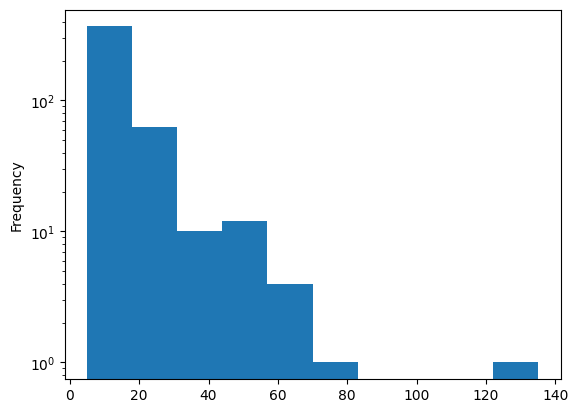

In [118]:
def extract_usable_rules(df: pd.DataFrame, min_segment_counts = 5, min_context_counts = 5) -> pd.DataFrame:
    segments = pd.concat([df["input"], df["output"]])
    contexts = pd.concat([df["env"], df["exception"]]).dropna()

    segments_counts = segments.value_counts()
    contexts_counts = contexts.value_counts()

    sample_segments = set(segments_counts[(segments_counts >= min_segment_counts)].index)
    sample_contexts = set(contexts_counts[(contexts_counts >= min_context_counts)].index)

    usable_inputs = df["input"].isin(sample_segments)
    usable_outputs = df["output"].isin(sample_segments)
    usable_envs = df["env"].isin(sample_contexts) | df["env"].isna()
    usable_exceptions = df["exception"].isin(sample_contexts) | df["exception"].isna()

    return df[usable_inputs & usable_outputs & usable_envs & usable_exceptions]

MIN_PART_COUNTS = 5
MIN_SECTION_SIZE = 5

usable_rules_df = extract_usable_rules(rules_df, min_segment_counts=MIN_PART_COUNTS, min_context_counts=MIN_PART_COUNTS)

group_counts = usable_rules_df['section_index'].groupby(usable_rules_df['section_index']).transform('size')
usable_rules_df = usable_rules_df[group_counts >= MIN_SECTION_SIZE]
print(f"Usable rules: {usable_rules_df.shape[0]}")

section_sizes = usable_rules_df['section_index'].value_counts()
# display(section_sizes.value_counts().sort_index())

section_sizes.plot.hist(log=True)
section_sizes_rounded = 5 * (section_sizes/5).astype(int)
display(section_sizes_rounded.value_counts().sort_index())

display(usable_rules_df.head(5))


In [ ]:
# Most sections have 5-10 rules. 
# We need to train on series of the same length (I guess)
# so we can potentially reuse some of the data in 
# long sections by partitioning the rules in windows 
# of the same size. Although, we probably shouldn't duplicate
# too much data.

min_size_sections = section_sizes[section_sizes == MIN_SECTION_SIZE]
gt_min_size_sections = section_sizes[section_sizes > MIN_SECTION_SIZE]

print(f"  min size sections: {min_size_sections.shape[0]}")
print(f"> min size sections: {gt_min_size_sections.shape[0]}")

import numpy as np

def extract_windows(sequence, window_size=5, K=11):
    L = len(sequence)
    if L < window_size:
        return []
    
    # Tier 1: Short sections (5 to 10) -> Stride 1
    if L <= 10:
        starts = range(0, L - window_size + 1, 1)
        
    # Tier 2: Medium sections (11 to 25) -> Stride 2 + ensure last window is included
    elif L <= 25:
        starts = list(range(0, L - window_size + 1, 2))
        if starts[-1] != L - window_size:
            starts.append(L - window_size)
            
    # Tier 3: Long tail (26+) -> Exactly K + 1 (12) evenly spaced windows
    else:
        starts = np.linspace(0, L - window_size, K + 1, dtype=int)
        
    return [sequence[i : i + window_size] for i in starts]


  min size sections: 51
> min size sections: 407


Based on your 458 sections, set K = 11 (capping long sections at 12 windows).

Why K = 11 Fits Your Distribution

Your dataset breaks down cleanly across three size tiers:
• Median length: 10 events (52.6% of your sections are 5–10 events).
• 75th percentile: 15 events.
• 90th percentile: ~23 events (only 8.3% of your sections exceed 25 events).
If you used a uniform stride of 1 across everything, those rare sections (>30 events) make up less than 7% of your dataset yet would generate 30.8% of all training windows (1,357 out of 4,406 windows). Setting K = 11 keeps total training samples high (~2,360 windows) while preventing the long tail from hijacking your model.

Recommended Schedule for Your Data


Section Length (L)	Share of Sections	Strategy	Windows per Section	Total Training Windows
5–10 events	52.6% (241)	Stride = 1	1 to 6	745 (31.5%)
11–25 events	39.1% (179)	Stride = 2 (+ final window)	4 to 11	1,161 (49.2%)
26–135 events	8.3% (38)	Dynamic stride (K = 11)	Capped at 12	456 (19.3%)

(Note: For the 26–135 group, using np.linspace(0, L - 5, 12, dtype=int) guarantees every long section produces exactly 12 evenly spaced windows from start to finish, including the single 135-event outlier.)

Python Implementation

```python
import numpy as np

def extract_windows(sequence, window_size=5, K=11):
    L = len(sequence)
    if L < window_size:
        return []
    
    # Tier 1: Short sections (5 to 10) -> Stride 1
    if L <= 10:
        starts = range(0, L - window_size + 1, 1)
        
    # Tier 2: Medium sections (11 to 25) -> Stride 2 + ensure last window is included
    elif L <= 25:
        starts = list(range(0, L - window_size + 1, 2))
        if starts[-1] != L - window_size:
            starts.append(L - window_size)
            
    # Tier 3: Long tail (26+) -> Exactly K + 1 (12) evenly spaced windows
    else:
        starts = np.linspace(0, L - window_size, K + 1, dtype=int)
        
    return [sequence[i : i + window_size] for i in starts]
```

If you'd like to adjust the balance further, let me know:

• Whether your target label is predicted per-window or inherited from the whole section
• If sequence order near the end of long sections matters more than the beginning
I can tweak the spacing (e.g., denser sampling near the tail) to match your prediction task.
Show Code


In [103]:
# try using cleaned index rules (they may be a bit simpler syntactically)

# just use the last validation run for now
# COMPILED_RULES_PATH = "../diagnostics/inventory/rule-inventory-success.csv"
# compiled_rules_df = pd.read_csv(COMPILED_RULES_PATH)[["section_index", "rule_id"]]
# valid_rule_ids = set(compiled_rules_df["rule_id"])

# if REGENERATE_INDEX_RULES:
#     with open(INDEX_YML_PATH, "r") as f:
#         rules_doc = yaml.load(f, Loader=yaml.SafeLoader)

#     rules = []
#     for s in rules_doc["sections"]:
#         for r in s.get("rules", []):
#             if r.get("status", "") == "skipped" or r["rule_id"] not in valid_rule_ids:
#                 continue
#             if "stages" in r and len(r["stages"]) > 1:
#                 for i in range(len(r["stages"]) - 1):
#                     rule = {
#                         "input": r["stages"][i],
#                         "output": r["stages"][i+1],
#                         "rule_id": r["rule_id"],
#                     }
#                     if "env" in r:
#                         rule["env"] = r["env"]
#                     if "exception" in r:
#                         rule["exception"] = r["exception"]
                        
#                     for j, rl in enumerate(split_condensed_rule(rule)):
#                         rules.append({"section_index": s["index"], "section_name": s["section"], "step_index": i, "c_index": j, **rl})

#     index_rules_df = pd.DataFrame(rules)[DF_COLS]
#     index_rules_df.to_csv(INDEX_RULES_CSV_PATH, index=False)
# else:
#     index_rules_df = pd.read_csv(INDEX_RULES_CSV_PATH)

# print(index_rules_df.shape)
# index_rules_df.head(5)